# Financial Complaint and Severity Classification

Single-task vs multi-task Transformer–BiGRU models on the FINCORP dataset. See the README for the setup and results.


In [ ]:
import pandas as pd
import os
import time
import csv
import random
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import f1_score, accuracy_score
from sklearn.utils.class_weight import compute_class_weight
from transformers import AutoTokenizer, AutoModel
from copy import deepcopy
from types import SimpleNamespace
import torch
import torch.nn as nn
from torch.optim import AdamW
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:

%cd /content/drive/My Drive/financial-complaints  # folder containing FINCORP.csv

df = pd.read_csv("FINCORP.csv")
df.sample(5)

/content/drive/My Drive/financial-complaints


,Domain,Complaint/ Opinion,Complaint Label,Severity level,Sentiment,Emotion
2246,Financial Apps,@CRED_support @kunalb11 @CRED_club @jagograhak...,1,No explicit reproach,negative,sadness
2188,Transaction Failure,@StanChartHelpIN I am simply asking for an ema...,1,No explicit reproach,negative,sadness
5553,Stocks and investment,Today I had lunch with one of my acquaintance ...,0,Non-Complaint,neutral,other
1974,Transaction Failure,This transaction is expected to fail. Trying t...,1,No explicit reproach,negative,sadness
722,Customer Service,@TheOfficialSBI Can I collect form 35 on my fr...,1,No explicit reproach,negative,sadness


In [ ]:
df.shape

(6281, 6)

In [ ]:
df.groupby('Complaint Label').size()

,0
Complaint Label,
0,3132
1,3149


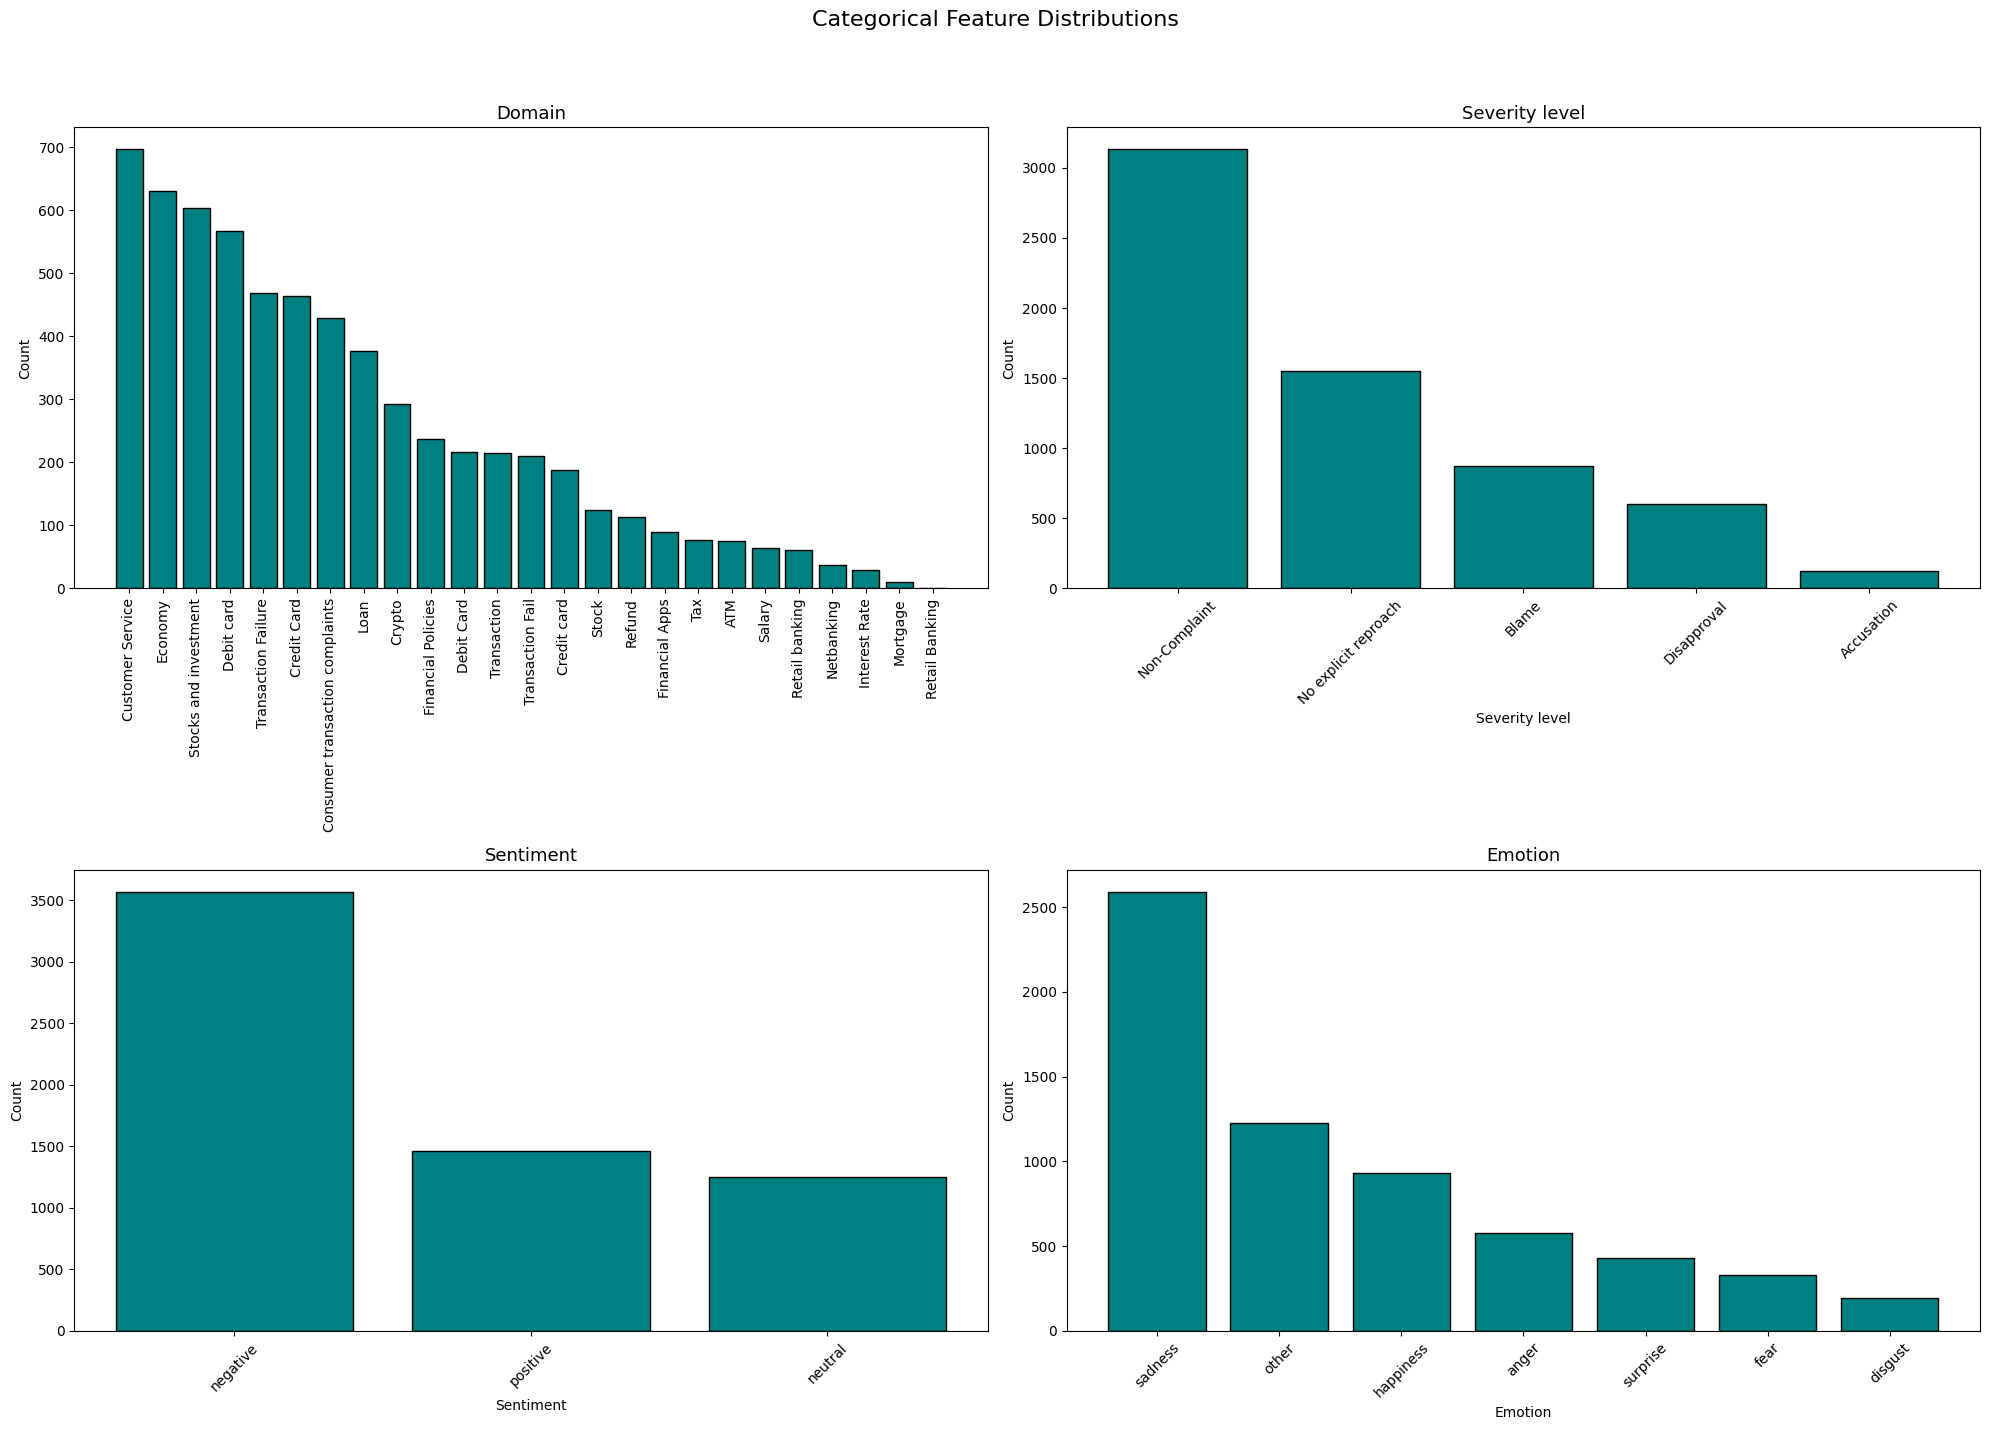

In [ ]:
# Bar plots for categorical feature distributions

categorical_cols = ['Domain', 'Severity level', 'Sentiment', 'Emotion']

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(20, 15))
axes = axes.flatten()


for i, col in enumerate(categorical_cols):
    value_counts = df[col].value_counts()
    axes[i].bar(value_counts.index, value_counts.values, color='teal', edgecolor='black')
    axes[i].set_title(col, fontsize=13)
    axes[i].set_ylabel('Count', fontsize=10)

    if col == 'Domain':
        axes[i].tick_params(axis='x', rotation=90)
        axes[i].set_xlabel('')
    else:
        axes[i].tick_params(axis='x', rotation=45)
        axes[i].set_xlabel(col, fontsize=10)

plt.suptitle("Categorical Feature Distributions", fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

In [ ]:
# Set seeds

SPLIT_SEED = 40
TRAINING_SEEDS = [40, 41, 42]

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

In [ ]:
# Set task labels and model names

TASK_LABEL_COLUMNS = {
    "complaint": "complaint_label",
    "severity": "severity_label",
    "emotion": "emotion_label",
    "sentiment": "sentiment_label",
}

MODEL_NAMES = {
    "roberta": "roberta-base",
    "distilbert": "distilbert-base-uncased",
    "finbert": "ProsusAI/finbert"
}

In [ ]:
# Encoding

df.rename(columns={'Complaint Label': 'complaint_label'}, inplace=True)

emotion_label = LabelEncoder()
df['emotion_label'] = emotion_label.fit_transform(df['Emotion'])

sentiment_label = LabelEncoder()
df['sentiment_label'] = sentiment_label.fit_transform(df['Sentiment'])

complaint_rows = df['complaint_label'] == 1
severity_label = LabelEncoder()
severity_label.fit(df.loc[complaint_rows, "Severity level"])
df['severity_label'] = -100
df.loc[complaint_rows, "severity_label"] = severity_label.transform(df.loc[complaint_rows, "Severity level"])

# Train/Validation/Test set split

train_df, val_test_df = train_test_split(df, test_size=0.40, random_state=SPLIT_SEED, stratify=df['severity_label'])
val_df, test_df = train_test_split(val_test_df, test_size=0.75, random_state=SPLIT_SEED, stratify=val_test_df['severity_label'])

print(df.shape, train_df.shape, val_df.shape, test_df.shape)
total = df.shape[0]
print(f'{train_df.shape[0]/total*100:.0f}%, {val_df.shape[0]/total*100:.0f}%, {test_df.shape[0]/total*100:.0f}%')

# Compute class weights for severity label

train_severity_labels = train_df[train_df["severity_label"] != -100]["severity_label"]
cs_class_weights = compute_class_weight(
    class_weight = "balanced",
    classes = np.unique(train_severity_labels),
    y = train_severity_labels)

# Convert to a PyTorch tensor
cs_class_weights_tensor = torch.tensor(cs_class_weights, dtype=torch.float)
print("CS Class Weights:", cs_class_weights_tensor)


(6281, 9) (3768, 9) (628, 9) (1885, 9)
60%, 10%, 30%
CS Class Weights: tensor([6.4692, 0.8995, 1.3046, 0.5083])


In [ ]:
# Set configurations

tasks_config = {
    "complaint": int(df["complaint_label"].nunique()),
    "severity": len(severity_label.classes_),
    "emotion": int(df["emotion_label"].nunique()),
    "sentiment": int(df["sentiment_label"].nunique())
}

args = SimpleNamespace(
    models=["roberta", "distilbert", "finbert"],
    primary_tasks=["CI", "CS"],
    epochs=3,
    batch_size=32,
    encoder_lr=5e-5,
    head_lr=1e-3,
    dropout=0.3,
    max_length=50,
    gru_hidden_size=128,
    output_csv="exclude_results.csv",
)

In [ ]:
# Prepare dataset as input

class FINCORPDataset(Dataset):
    def __init__(self, df, tokenizer, max_length=50):
        self.df = df.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_length = max_length
        self.texts = self.df['Complaint/ Opinion'].fillna("").astype(str).tolist()

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        encoded = self.tokenizer(
            self.texts[index],
            add_special_tokens=True,
            max_length=self.max_length,
            padding="max_length",
            truncation=True,
            return_tensors="pt",
        )

        labels = {}
        for task, col in TASK_LABEL_COLUMNS.items():
            labels[task] = torch.tensor(int(self.df.loc[index, col]), dtype=torch.long)

        return {
            "input_ids": encoded["input_ids"].squeeze(0),
            "attention_mask": encoded["attention_mask"].squeeze(0),
            "labels": labels,
        }

def make_loader(df, tokenizer, batch_size, max_length, shuffle):
    dataset = FINCORPDataset(df, tokenizer, max_length=max_length)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)

In [ ]:
# Define one task-specific BiGRU classification head

class TaskBiGRUHead(nn.Module):
    def __init__(self, encoder_hidden_size, gru_hidden_size, num_labels, dropout):
        super().__init__()
        self.bigru = nn.GRU(
            input_size=encoder_hidden_size,
            hidden_size=gru_hidden_size,
            batch_first=True,
            bidirectional=True,
        )
        self.classifier = nn.Sequential(
            nn.Linear(gru_hidden_size * 2, gru_hidden_size),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(gru_hidden_size, gru_hidden_size // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(gru_hidden_size // 2, num_labels),
        )

    def forward(self, sequence_output, attention_mask):
        gru_output, _ = self.bigru(sequence_output)
        mask = attention_mask.unsqueeze(-1).float()
        pooled = (gru_output * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1.0)
        return self.classifier(pooled)

In [ ]:
# Define the full multi-task Transformer-BiGRU architecture

class MTLTransformerBiGRU(nn.Module):

    def __init__(self, model_name, tasks_config, active_tasks, gru_hidden_size=128, dropout=0.3):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(model_name)
        hidden_size = self.encoder.config.hidden_size
        self.heads = nn.ModuleDict(
            {
                task: TaskBiGRUHead(
                    encoder_hidden_size=hidden_size,
                    gru_hidden_size=gru_hidden_size,
                    num_labels=tasks_config[task],
                    dropout=dropout,
                )
                for task in active_tasks
            }
        )

    def forward(self, input_ids, attention_mask):
        outputs = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        sequence_output = outputs.last_hidden_state
        return {
            task: head(sequence_output, attention_mask)
            for task, head in self.heads.items()
        }

In [ ]:
# Set tokenizer

def build_tokenizer(model_name):
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    return tokenizer

In [ ]:
# Define training process

def train_epoch(model, loader, optimizer, base_criterion, cs_criterion, device, active_tasks, scaler=None, cs_weights=None):
    model.train()
    total_loss = 0.0

    for batch in tqdm(loader, desc="Training", leave=False):
        optimizer.zero_grad(set_to_none=True)
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = {task: value.to(device) for task, value in batch["labels"].items()}

        use_amp = device.type == "cuda"
        with torch.amp.autocast(device_type="cuda", enabled=use_amp):
            logits = model(input_ids=input_ids, attention_mask=attention_mask)
            loss = torch.tensor(0.0, device=device)
            for task in active_tasks:
              if (labels[task] != -100).sum() == 0:
                continue
              if task == "severity" and cs_weights is not None:
                loss += cs_criterion(logits[task], labels[task])
              else:
                loss += base_criterion(logits[task], labels[task])

        if loss.item() > 0:
          if use_amp and scaler is not None:
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
          else:
            loss.backward()
            optimizer.step()

        total_loss += loss.item()

    return total_loss / max(len(loader), 1)

In [ ]:
# Define evaluation process

def evaluate(model, loader, device, active_tasks):
    model.eval()
    all_targets = {task: [] for task in active_tasks}
    all_preds = {task: [] for task in active_tasks}

    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            logits = model(input_ids=input_ids, attention_mask=attention_mask)

            for task in active_tasks:
                targets = batch["labels"][task].numpy()
                preds = torch.argmax(logits[task], dim=1).cpu().numpy()

                if task == "severity":
                    keep = targets != -100
                    targets = targets[keep]
                    preds = preds[keep]

                all_targets[task].extend(targets.tolist())
                all_preds[task].extend(preds.tolist())

    metrics = {}
    for task in active_tasks:
        if len(all_targets[task]) == 0:
            continue
        metrics[task] = {
            "accuracy": accuracy_score(all_targets[task], all_preds[task]),
            "macro_f1": f1_score(
                all_targets[task],
                all_preds[task],
                average="macro",
                zero_division=0,
            ),
        }
    return metrics

In [ ]:
# Define tasks and primary metric name

def get_task_sets(primary_task):
    if primary_task == "CI":
        return [
            ("STL_CI", ("complaint",)),
            ("MTL_CI+ER", ("complaint", "emotion")),
            ("MTL_CI+SA", ("complaint", "sentiment")),
            ("MTL_CI+CS", ("complaint", "severity")),
            ("MTL_CI+ER+SA", ("complaint", "emotion", "sentiment")),
            ("MTL_CI+ER+CS", ("complaint", "emotion", "severity")),
            ("MTL_CI+SA+CS", ("complaint", "sentiment", "severity")),
            ("MTL_CI+CS+ER+SA", ("complaint", "severity", "emotion", "sentiment")),
        ]

    if primary_task == "CS":
        return [
            ("STL_CS", ("severity",)),
            ("MTL_CS+CI", ("severity", "complaint")),
            ("MTL_CS+ER", ("severity", "emotion")),
            ("MTL_CS+SA", ("severity", "sentiment")),
            ("MTL_CS+ER+SA", ("severity", "emotion", "sentiment")),
            ("MTL_CS+ER+CI", ("severity", "emotion", "complaint")),
            ("MTL_CS+SA+CI", ("severity", "sentiment", "complaint")),
            ("MTL_CS+CI+ER+SA", ("severity", "complaint", "emotion", "sentiment")),
        ]

    raise ValueError("primary_task must be CI or CS")


def primary_metric_name(primary_task):
    return "complaint" if primary_task == "CI" else "severity"

In [ ]:
# Running one experiment

def run_one_experiment(
    seed,
    model_key,
    model_name,
    run_name,
    active_tasks,
    primary_task,
    train_df,
    val_df,
    test_df,
    tasks_config,
    args,
    device,
    cs_weights=None
):
    tokenizer = build_tokenizer(model_name)

    train_loader = make_loader(
        train_df,
        tokenizer,
        batch_size=args.batch_size,
        max_length=args.max_length,
        shuffle=True,
    )
    val_loader = make_loader(
        val_df,
        tokenizer,
        batch_size=args.batch_size,
        max_length=args.max_length,
        shuffle=False,
    )
    test_loader = make_loader(
        test_df,
        tokenizer,
        batch_size=args.batch_size,
        max_length=args.max_length,
        shuffle=False,
    )

    model = MTLTransformerBiGRU(
        model_name=model_name,
        tasks_config=tasks_config,
        active_tasks=active_tasks,
        gru_hidden_size=args.gru_hidden_size,
        dropout=args.dropout,
    ).to(device)

    optimizer = AdamW([{"params": model.encoder.parameters(), "lr": args.encoder_lr},
                       {"params": model.heads.parameters(), "lr": args.head_lr}])

    base_criterion = nn.CrossEntropyLoss(ignore_index=-100)
    if cs_weights is not None:
      cs_criterion = nn.CrossEntropyLoss(weight=cs_weights.to(device), ignore_index=-100)
    else:
      cs_criterion = base_criterion

    scaler = torch.amp.GradScaler("cuda") if device.type == "cuda" else None

    best_state = None
    best_val_metrics = None
    best_score = -1.0
    metric_task = primary_metric_name(primary_task)

    start_time = time.time()

    for epoch in range(args.epochs):
        train_loss = train_epoch(
            model=model,
            loader=train_loader,
            optimizer=optimizer,
            base_criterion=base_criterion,
            cs_criterion=cs_criterion,
            device=device,
            active_tasks=active_tasks,
            scaler=scaler,
            cs_weights=cs_weights
        )
        val_metrics = evaluate(model, val_loader, device, active_tasks)
        score = val_metrics[metric_task]["macro_f1"]

        print(
            f"{model_key} | {run_name} | epoch {epoch + 1}/{args.epochs} | "
            f"loss={train_loss:.4f} | val_{metric_task}_macro_f1={score:.4f}"
        )

        if score > best_score:
            best_score = score
            best_state = deepcopy(model.state_dict())
            best_val_metrics = val_metrics

    end_time = time.time()
    train_time = end_time - start_time

    os.makedirs("saved_models", exist_ok=True)
    model_filename = f"saved_models/{model_key}_{primary_task}_{run_name}_seed{seed}.pt"
    torch.save(best_state, model_filename)
    print(f"   -> Saved best model to: {model_filename}")

    return best_val_metrics, train_time

In [ ]:
# Getting and writing result

def flatten_result(seed, model_key, primary_task, run_name, active_tasks, split, metrics, train_time=0.0):
    metric_task = primary_metric_name(primary_task)
    row = {
        "seed": seed,
        "model": model_key,
        "primary_task": primary_task,
        "experiment": run_name,
        "active_tasks": "+".join(active_tasks),
        "split": split,
        "primary_accuracy": metrics[metric_task]["accuracy"],
        "primary_macro_f1": metrics[metric_task]["macro_f1"],
        "train_time_seconds": train_time
    }

    for task, task_metrics in metrics.items():
        row[f"{task}_accuracy"] = task_metrics["accuracy"]
        row[f"{task}_macro_f1"] = task_metrics["macro_f1"]

    return row


def write_results(path, rows):
    if not rows:
        return

    fieldnames = []
    for row in rows:
        for key in row:
            if key not in fieldnames:
                fieldnames.append(key)

    with open(path, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(rows)

In [ ]:
# Get data for primary task

def get_data_for_primary_task(primary_task, train_df, val_df, test_df):
    return train_df, val_df, test_df

In [ ]:
# Run main execution

def main():
    print("Task output sizes:", tasks_config)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    rows = []

    for seed in TRAINING_SEEDS:
        for model_key in args.models:
            model_name = MODEL_NAMES[model_key]

            for primary_task in args.primary_tasks:
              for run_name, active_tasks in get_task_sets(primary_task):
                    print(f"\n=== seed {seed} | {model_key} | {primary_task} | {run_name} ===")
                    set_seed(seed)

                    exp_train_df, exp_val_df, exp_test_df = get_data_for_primary_task(primary_task, train_df, val_df, test_df)

                    val_metrics, train_time = run_one_experiment(
                        seed=seed,
                        model_key=model_key,
                        model_name=model_name,
                        run_name=run_name,
                        active_tasks=active_tasks,
                        primary_task=primary_task,
                        train_df=exp_train_df,
                        val_df=exp_val_df,
                        test_df=exp_test_df,
                        tasks_config=tasks_config,
                        args=args,
                        device=device,
                        cs_weights=cs_class_weights_tensor if primary_task == "CS" else None
                    )

                    rows.append(
                        flatten_result(
                            seed,
                            model_key,
                            primary_task,
                            run_name,
                            active_tasks,
                            "validation",
                            val_metrics,
                            train_time=train_time
                        )
                    )

                    print(f"   -> Training completed in {train_time:.2f} seconds")
                    write_results(args.output_csv, rows)

    write_results(args.output_csv, rows)
    print(f"\nSaved results to {os.path.abspath(args.output_csv)}")

main()

Task output sizes: {'complaint': 2, 'severity': 4, 'emotion': 7, 'sentiment': 3}

=== seed 40 | roberta | CI | STL_CI ===


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.bias         | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
pooler.dense.bias               | MISSING    | 
pooler.dense.weight             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Training:   0%|          | 0/118 [00:00<?, ?it/s]

...

finbert | MTL_CS+CI+ER+SA | epoch 1/3 | loss=3.6467 | val_severity_macro_f1=0.4036


Training:   0%|          | 0/118 [00:00<?, ?it/s]

finbert | MTL_CS+CI+ER+SA | epoch 2/3 | loss=2.8696 | val_severity_macro_f1=0.4480


Training:   0%|          | 0/118 [00:00<?, ?it/s]

finbert | MTL_CS+CI+ER+SA | epoch 3/3 | loss=2.4283 | val_severity_macro_f1=0.5278
   -> Saved best model to: saved_models/finbert_CS_MTL_CS+CI+ER+SA_seed42.pt
   -> Training completed in 53.75 seconds

Saved results to /content/drive/MyDrive/financial-complaints/exclude_results.csv


In [ ]:
# Calculate statistical significance (mean with standard deviation, p-value, training time)

def calculate_paper_exact_table(csv_path):
    df = pd.read_csv(csv_path)
    df = df.drop_duplicates(subset=['seed', 'model', 'primary_task', 'experiment', 'split'], keep='last')
    val_df = df[df['split'] == 'validation']

    metrics = {
        'Accuracy (%)': 'primary_accuracy',
        'F1-score(%)': 'primary_macro_f1',
        'Time(s)': 'train_time_seconds'
    }

    for (model_name, primary_task), group in val_df.groupby(['model', 'primary_task']):
        print(f"\n{'='*60}")
        print(f"Model: {model_name} | Primary Task: {primary_task}")
        print(f"{'='*60}")

        stl_exp_name = f"STL_{primary_task}"
        baseline_data = group[group['experiment'] == stl_exp_name]

        if len(baseline_data) < 2:
            print(f"Not enough seeds to calculate significance for {model_name}.")
            continue

        summary_rows = []
        experiments = group['experiment'].unique()

        for exp in experiments:
            row_data = {'Model': exp}
            exp_data = group[group['experiment'] == exp]

            for display_name, col_name in metrics.items():

                multiplier = 100 if "(%)" in display_name else 1
                mean_val = exp_data[col_name].mean() * multiplier
                std_val = exp_data[col_name].std() * multiplier

                sig_star = ""
                if exp != stl_exp_name and len(exp_data) > 1:
                    common_seeds = set(baseline_data['seed']).intersection(set(exp_data['seed']))

                    stl_sorted = baseline_data[baseline_data['seed'].isin(common_seeds)].sort_values('seed')[col_name].values
                    exp_sorted = exp_data[exp_data['seed'].isin(common_seeds)].sort_values('seed')[col_name].values

                    if np.std(stl_sorted) > 0 or np.std(exp_sorted) > 0:
                        t_stat, p_val = stats.ttest_rel(exp_sorted, stl_sorted)
                        if p_val < 0.05:
                            sig_star = "*" # Add asterisk if significant

                row_data[display_name] = f"{mean_val:.2f}{sig_star} \u00b1 {std_val:.2f}"

            summary_rows.append(row_data)

        summary_df = pd.DataFrame(summary_rows)
        print(summary_df.to_string(index=False))

calculate_paper_exact_table("exclude_results.csv")


Model: distilbert | Primary Task: CI
          Model  Accuracy (%)   F1-score(%)       Time(s)
         STL_CI  97.08 ± 0.18  97.08 ± 0.18  29.64 ± 0.11
      MTL_CI+ER  96.55 ± 0.49  96.55 ± 0.49 30.95* ± 0.30
      MTL_CI+SA  96.82 ± 0.32  96.81 ± 0.32 30.78* ± 0.23
      MTL_CI+CS 96.44* ± 0.09 96.44* ± 0.09 30.63* ± 0.21
   MTL_CI+ER+SA  97.03 ± 0.40  97.03 ± 0.40 31.97* ± 0.31
   MTL_CI+ER+CS  96.50 ± 0.42  96.50 ± 0.42 31.87* ± 0.25
   MTL_CI+SA+CS  96.50 ± 0.42  96.50 ± 0.42 31.89* ± 0.37
MTL_CI+CS+ER+SA  96.97 ± 0.16  96.97 ± 0.16 32.96* ± 0.30

Model: distilbert | Primary Task: CS
          Model Accuracy (%)  F1-score(%)       Time(s)
         STL_CS 61.16 ± 1.43 47.01 ± 1.85  29.59 ± 0.15
      MTL_CS+CI 61.59 ± 8.25 49.88 ± 4.85 31.05* ± 0.42
      MTL_CS+ER 63.49 ± 0.63 49.33 ± 1.27 31.11* ± 0.26
      MTL_CS+SA 56.40 ± 6.51 48.67 ± 4.07 30.89* ± 0.36
   MTL_CS+ER+SA 56.83 ± 2.86 48.94 ± 1.03 31.93* ± 0.32
   MTL_CS+ER+CI 63.39 ± 2.38 47.84 ± 1.59 32.10* ± 0.18
   MTL_CS+

In [ ]:
# Final test

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

def evaluate_test_set(test_df, tasks_config, args, device, seed=40):
    print("Evaluating models on the Test Set...\n")
    print(f"{'Model':<12} | {'Task':<4} | {'Experiment':<16} | {'Test Acc':<8} | {'Test F1':<8}")
    print("-" * 60)

    test_results = []

    for model_key in args.models:
        model_name = MODEL_NAMES[model_key]
        tokenizer = build_tokenizer(model_name)

        for primary_task in args.primary_tasks:
            task_sets = get_task_sets(primary_task)

            for run_name, active_tasks in task_sets:

                _, _, current_test_df = get_data_for_primary_task(primary_task, test_df, test_df, test_df)

                test_loader = make_loader(
                    current_test_df,
                    tokenizer,
                    batch_size=args.batch_size,
                    max_length=args.max_length,
                    shuffle=False,
                )

                model = MTLTransformerBiGRU(
                    model_name=model_name,
                    tasks_config=tasks_config,
                    active_tasks=active_tasks,
                    gru_hidden_size=args.gru_hidden_size,
                    dropout=args.dropout,
                ).to(device)

                model_filename = f"saved_models/{model_key}_{primary_task}_{run_name}_seed{seed}.pt"

                if not os.path.exists(model_filename):
                    continue

                model.load_state_dict(torch.load(model_filename, map_location=device))

                test_metrics = evaluate(model, test_loader, device, active_tasks)

                metric_task = primary_metric_name(primary_task)
                test_acc = test_metrics[metric_task]["accuracy"]
                test_f1 = test_metrics[metric_task]["macro_f1"]

                print(f"{model_key:<12} | {primary_task:<4} | {run_name:<16} | {test_acc:.4f}   | {test_f1:.4f}")

                test_results.append({
                    "model": model_key,
                    "primary_task": primary_task,
                    "experiment": run_name,
                    "test_accuracy": test_acc,
                    "test_macro_f1": test_f1
                })

    return pd.DataFrame(test_results)

test_results_df = evaluate_test_set(test_df, tasks_config, args, device, seed=SPLIT_SEED)

try:
    val_results_df = pd.read_csv(args.output_csv)
    val_results_df = val_results_df[val_results_df['seed'] == SPLIT_SEED]

    final_report_df = pd.merge(
        test_results_df,
        val_results_df[['model', 'primary_task', 'experiment', 'train_time_seconds']],
        on=['model', 'primary_task', 'experiment'],
        how='left'
    )

    final_report_df['train_time_seconds'] = final_report_df['train_time_seconds'].round(2)

    print("\n\n=== FINAL TEST REPORT ===")
    display(final_report_df)

    final_report_df.to_csv("latest_test_results.csv", index=False)
    print("Saved final test results to 'latest_test_results.csv'")

except FileNotFoundError:
    print(f"\nCould not find {args.output_csv} to merge training times. Showing test metrics only:")
    display(test_results_df)

Using device: cuda
Evaluating models on the Test Set...

Model        | Task | Experiment       | Test Acc | Test F1 
------------------------------------------------------------


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.bias         | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
pooler.dense.bias               | MISSING    | 
pooler.dense.weight             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.bias         | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
pooler.dense.bias               | MISSING    | 
pooler.dense.weight             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: ProsusAI/finbert
Key                          | Status     |  | 
-----------------------------+------------+--+-
classifier.weight            | UNEXPECTED |  | 
bert.embeddings.position_ids | UNEXPECTED |  | 
classifier.bias              | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


finbert      | CS   | MTL_CS+CI+ER+SA  | 0.6529   | 0.4867


=== FINAL TEST REPORT ===


,model,primary_task,experiment,test_accuracy,test_macro_f1,train_time_seconds
0,roberta,CI,MTL_CI+ER,0.958090,0.958089,52.47
1,roberta,CI,MTL_CI+SA,0.956499,0.956495,52.91
2,roberta,CI,MTL_CI+CS,0.950133,0.950104,52.85
3,roberta,CI,MTL_CI+ER+SA,0.955438,0.955436,54.18
4,roberta,CI,MTL_CI+ER+CS,0.957560,0.957554,53.77
5,roberta,CI,MTL_CI+SA+CS,0.960212,0.960210,53.84
6,roberta,CI,MTL_CI+CS+ER+SA,0.953846,0.953842,54.75
7,roberta,CS,STL_CS,0.562963,0.342197,51.09
8,roberta,CS,MTL_CS+CI,0.650794,0.492666,52.78
9,roberta,CS,MTL_CS+ER,0.459259,0.411027,52.59


Saved final test results to 'latest_test_results.csv'


In [ ]:
# Format the results

def format_metrics(df, model, primary_task):

    filtered_df = df[(df['model'] == model) & (df['primary_task'] == primary_task)]

    if filtered_df.empty:
        return

    print("=" * 60)
    print(f"Model: {model} | Primary Task: {primary_task}")
    print("=" * 60)
    print(f"{'Model':>15} {'Accuracy (%)':>13} {'F1-score(%)':>13} {'Time(s)':>13}")

    grouped = filtered_df.groupby('experiment')

    experiment_order = []
    if primary_task == "CI":
        experiment_order = [
            "STL_CI", "MTL_CI+ER", "MTL_CI+SA", "MTL_CI+CS",
            "MTL_CI+ER+SA", "MTL_CI+ER+CS", "MTL_CI+SA+CS", "MTL_CI+CS+ER+SA"
        ]
    else:
         experiment_order = [
            "STL_CS", "MTL_CS+CI", "MTL_CS+ER", "MTL_CS+SA",
            "MTL_CS+ER+SA", "MTL_CS+ER+CI", "MTL_CS+SA+CI", "MTL_CS+CI+ER+SA"
        ]

    baseline_time = 0
    if f"STL_{primary_task}" in grouped.groups:
         baseline_time = grouped.get_group(f"STL_{primary_task}")['train_time_seconds'].mean()

    for exp in experiment_order:
        if exp in grouped.groups:
            exp_data = grouped.get_group(exp)

            acc_mean = exp_data['primary_accuracy'].mean() * 100
            acc_std = exp_data['primary_accuracy'].std() * 100

            f1_mean = exp_data['primary_macro_f1'].mean() * 100
            f1_std = exp_data['primary_macro_f1'].std() * 100

            time_mean = exp_data['train_time_seconds'].mean()
            time_std = exp_data['train_time_seconds'].std()

            acc_str = f"{acc_mean:.2f} \u00B1 {acc_std:.2f}"
            f1_str = f"{f1_mean:.2f} \u00B1 {f1_std:.2f}"

            time_marker = "*" if (time_mean > baseline_time + 0.5 and exp != f"STL_{primary_task}") else ""
            time_str = f"{time_mean:.2f}{time_marker} \u00B1 {time_std:.2f}"

            print(f"{exp:>15} {acc_str:>13} {f1_str:>13} {time_str:>13}")

    print("\n")

csv_file_path = "latest_exclude_results.csv"

results_df = pd.read_csv(csv_file_path)
models = ["distilbert", "finbert", "roberta"]
primary_tasks = ["CI", "CS"]

for model in models:
  for p_task in primary_tasks:
    format_metrics(results_df, model, p_task)

results_df.to_csv('final_test_result.csv')